In [ ]:
# LIBRARIES
from google.colab import drive, files
import zipfile

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

In [ ]:
print("~/~/~/ Plant Disease Classification Model ~/~/~")

# DATASET & TESTSET LOADING
dir_path = "/content/drive/MyDrive/Plant_Disease_Dataset/trainset.zip"
tst_path = "/content/drive/MyDrive/Plant_Disease_Dataset/testset.zip"
extract_path = "/content/DATASET"

drive.mount('/content/drive')

with zipfile.ZipFile(dir_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
with zipfile.ZipFile(tst_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Data has been loaded successfully!")

~/~/~/ Plant Disease Classification Model ~/~/~
Mounted at /content/drive
Data has been loaded successfully!


In [ ]:
# DATA SETUP
DIR_NAME = "/content/DATASET/TRAINSET"
TEST_DIR = "/content/DATASET/TESTSET"
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    directory=DIR_NAME,
    validation_split=0.2,
    subset="training",
    label_mode="int",
    batch_size=BATCH_SIZE,
    seed=296,
    image_size=(224, 224)
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory=DIR_NAME,
    validation_split=0.2,
    subset="validation",
    label_mode="int",
    batch_size=BATCH_SIZE,
    seed=296,
    image_size=(224, 224)
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    directory=TEST_DIR,
    label_mode="int",
    seed=296,
    image_size=(224, 224),
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets are ready to use, with classes: ", NUM_CLASSES)

Found 17888 files belonging to 12 classes.
Using 14311 files for training.
Found 17888 files belonging to 12 classes.
Using 3577 files for validation.
Found 203 files belonging to 12 classes.
Datasets are ready to use, with classes:  12


In [ ]:
# MOBILENETV2 MODEL TUNNING
FREEZE_LAYERS = -75
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = True

# freezing only earlier layers, so that last layers can learn
for layer in base_model.layers[:FREEZE_LAYERS]:
  layer.trainable = False

for layer in base_model.layers:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False

# data augmenation
data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

# tunning model finely
input = tf.keras.Input(shape=(224, 224, 3))
x = data_aug(input)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.models.Model(input, output)

# callback fx
cb = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
      tf.keras.callbacks.ModelCheckpoint("best.keras", monitor="val_loss", save_best_only=True)]

# model compilation & summary
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()

# model fitting
model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    callbacks=cb
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 2,027,788 (7.74 MB)

 Non-trainable params: 245,568 (959.25 KB)

Epoch 1/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 67s 60ms/step - accuracy: 0.8380 - loss: 0.4795 - val_accuracy: 0.8845 - val_loss: 0.3315
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 51s 57ms/step - accuracy: 0.9370 - loss: 0.1918 - val_accuracy: 0.9351 - val_loss: 0.1879
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 81s 56ms/step - accuracy: 0.9523 - loss: 0.1444 - val_accuracy: 0.9117 - val_loss: 0.2630
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 51s 57ms/step - accuracy: 0.9630 - loss: 0.1149 - val_accuracy: 0.9430 - val_loss: 0.1818
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 50s 56ms/step - accuracy: 0.9688 - loss: 0.0933 - val_accuracy: 0.9282 - val_loss: 0.2162
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 86s 61ms/step - accuracy: 0.9723 - loss: 0.0843 - val_accuracy: 0.9712 - val_loss: 0.0829
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 49s 55ms/step - accuracy: 0.9724 - loss: 0.0847 - val_accuracy: 0.9460 - val_loss: 0.1840
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 83s 56ms/step - accuracy: 0.9774 - loss: 0.0703 - 

7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 473ms/step


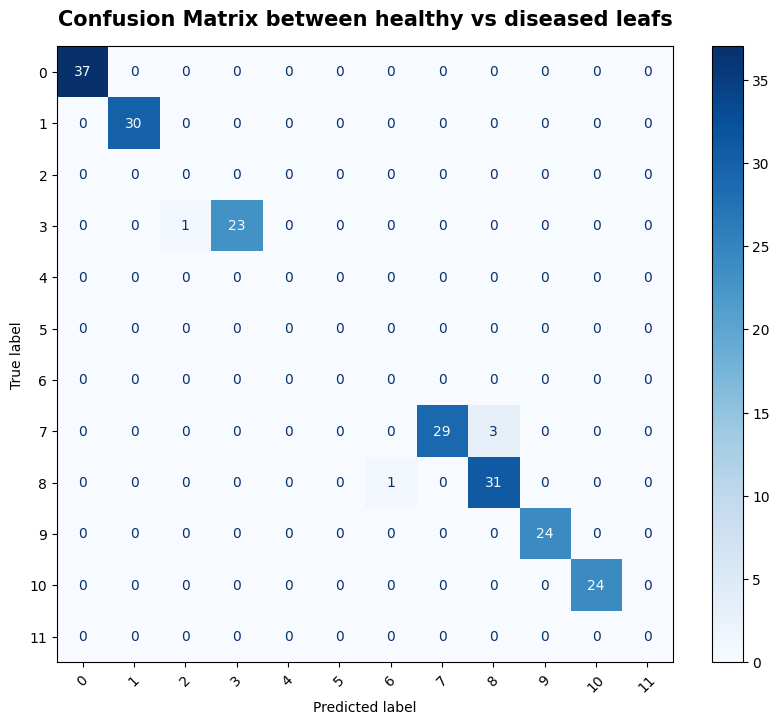

Accuracy: 97.5%
Classification Report:
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       1.00      1.00      1.00        37
                     Pepper__bell___healthy       1.00      1.00      1.00        30
                      Tomato_Bacterial_spot       0.00      0.00      0.00         0
                        Tomato_Early_blight       1.00      0.96      0.98        24
                         Tomato_Late_blight       0.00      0.00      0.00         0
                           Tomato_Leaf_Mold       0.00      0.00      0.00         0
                  Tomato_Septoria_leaf_spot       0.00      0.00      0.00         0
Tomato_Spider_mites_Two_spotted_spider_mite       1.00      0.91      0.95        32
                        Tomato__Target_Spot       0.91      0.97      0.94        32
      Tomato__Tomato_YellowLeaf__Curl_Virus       1.00      1.00      1.00        24
                Tomato__T

In [ ]:
# model testing
prob = model.predict(test_ds)
y_pred = np.argmax(prob, axis=1)
y_true = np.concatenate([y.numpy() for x, y in test_ds])

class_labels = np.arange(NUM_CLASSES)

# evaluation
ac = accuracy_score(y_true, y_pred) * 100
cr = classification_report(y_true, y_pred, labels=class_labels, target_names=class_names, zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=class_labels)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
fig, ax = plt.subplots(figsize=(10, 8))
display.plot(cmap="Blues", values_format="d", xticks_rotation=45, colorbar=True, ax=ax)
plt.title("Confusion Matrix between healthy vs diseased leafs", fontsize=15, fontweight="bold", pad=15)
plt.show()

print(f"Accuracy: {round(ac, 1)}%")
print(f"Classification Report:\n{cr}")
print(f"Confusion Matrix:\n{cm}")

In [ ]:
# MODEL SAVING AND DOWNLOADING
model.save("plant_disease_model.keras")
files.download("plant_disease_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>